# Análise Exploratória de Dados (EDA) — Projeto Extensionista: Enchentes RS & INCT SIMAI

Pipeline modular e reprodutível para limpeza, auditoria de inconsistências, tratamento sistemático de dados nulos/geoespaciais, integração e análise exploratória:
1. **Base Externa (Shapefile ANA/SGB — Vulnerabilidade a Inundações no Brasil):** ingestão local a partir de `Brasil_vulnerabilidade_inundacoes/Brasil_vulnerabilidade_inundacoes.shp` utilizando `geopandas`, filtragem para o Rio Grande do Sul e higienização documentada.
2. **Base Principal (`data.json` — Simulação INCT SIMAI, opcional/automática):** conversão para formato longo, auditoria sistemática das inconsistências e tratamento documentado.
3. **Integração e Visualizações Comentadas (EDA):** cruzamento, mapas temáticos de vulnerabilidade/risco, distribuição por classes e indicadores críticos no Rio Grande do Sul.

## 1. Configuração do Ambiente e Imports

In [1]:
import os
import json
import warnings
import unicodedata
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

os.environ['SHAPE_RESTORE_SHX'] = 'YES'
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
plt.rcParams['figure.dpi'] = 120

## 2. Parâmetros e Caminhos dos Arquivos

In [2]:
BASE_DIR = '/home/jo-o-antonio/Downloads/projeto_cpa'
CAMINHO_SHP = os.path.join(BASE_DIR, 'Brasil_vulnerabilidade_inundacoes', 'Brasil_vulnerabilidade_inundacoes.shp')
CAMINHO_SBN = os.path.join(BASE_DIR, 'Brasil_vulnerabilidade_inundacoes', 'Brasil_vulnerabilidade_inundacoes.sbn')
CAMINHO_JSON = os.path.join(BASE_DIR, 'data.json')
CAMINHO_SAIDA_GEOJSON = os.path.join(BASE_DIR, 'rs_vulnerabilidade_inundacoes_tratado.geojson')

## 3. Funções Modulares de Ingestão, Diagnóstico e Higienização

In [3]:
def normalizar_texto(valor):
    if not isinstance(valor, str):
        return valor
    limpo = unicodedata.normalize('NFC', valor.strip())
    return limpo

def verificar_arquivos_shapefile(caminho_shp, caminho_sbn):
    base = os.path.splitext(caminho_shp)[0]
    extensoes = ['.shp', '.shx', '.dbf', '.prj', '.cpg', '.sbx']
    status = {ext: os.path.exists(base + ext) for ext in extensoes}
    status['.sbn'] = os.path.exists(caminho_sbn)
    return status

def carregar_geodados(caminho_shp):
    for enc in ['utf-8', 'latin1', 'cp1252']:
        try:
            gdf = gpd.read_file(caminho_shp, encoding=enc)
            gdf.attrs['encoding_utilizado'] = enc
            return gdf
        except UnicodeDecodeError:
            continue
    raise ValueError('Falha ao decodificar o Shapefile com utf-8, latin1 ou cp1252.')

def diagnosticar_qualidade_geodados(gdf, etapa='BRUTO'):
    diag = {
        'etapa': etapa,
        'total_registros': int(len(gdf)),
        'crs': str(gdf.crs),
        'geometrias_nulas': int(gdf.geometry.isna().sum()),
        'geometrias_vazias': int(gdf.geometry.is_empty.sum()),
        'geometrias_invalidas': int((~gdf.geometry.is_valid).sum()),
        'duplicados_tabulares': int(gdf.drop(columns='geometry').duplicated().sum())
    }
    tabela_nulos = pd.DataFrame({
        'tipo': gdf.dtypes.astype(str),
        'nulos_qtd': gdf.isna().sum(),
        'nulos_pct': (gdf.isna().mean() * 100).round(4),
        'unicos': gdf.nunique(dropna=True)
    })
    return diag, tabela_nulos

def tratar_geodados_completo(gdf_bruto):
    gdf = gdf_bruto.copy()
    historico = []

    # 1. Remoção de geometrias nulas ou vazias
    n_antes = len(gdf)
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
    historico.append(f'Geometrias nulas/vazias removidas: {n_antes - len(gdf)}')

    # 2. Reparo topológico de polígonos inválidos
    inv = int((~gdf.geometry.is_valid).sum())
    if inv > 0:
        gdf['geometry'] = gdf['geometry'].buffer(0)
    historico.append(f'Geometrias inválidas reparadas via buffer(0): {inv}')

    # 3. Padronização de strings e conversão de sentinelas vazias para NaN
    cols_texto = [c for c in gdf.select_dtypes(include=['object', 'string']).columns if c != 'geometry']
    sentinelas = {'', 'None', 'none', 'NULL', 'null', 'N/A', 'NA', 'nan', 'NaN', '-', '--', 'Sem informação'}
    for col in cols_texto:
        gdf[col] = gdf[col].apply(normalizar_texto)
        gdf[col] = gdf[col].replace(list(sentinelas), np.nan)

    # 4. Filtragem para o Rio Grande do Sul (UF == RS ou código IBGE 43)
    col_uf = next((c for c in gdf.columns if c.upper() in ['SG_UF', 'UF', 'SIGLA_UF', 'ESTADO']), None)
    col_ibge = next((c for c in gdf.columns if any(k in c.upper() for k in ['CD_MUN', 'IBGE', 'GEOCOD'])), None)
    if col_uf:
        gdf = gdf[gdf[col_uf].astype(str).str.upper().isin(['RS', 'RIO GRANDE DO SUL'])].copy()
        historico.append(f'Recorte RS aplicado via {col_uf}: {len(gdf)} registros mantidos')
    elif col_ibge:
        gdf = gdf[gdf[col_ibge].astype(str).str.startswith('43')].copy()
        historico.append(f'Recorte RS aplicado via {col_ibge} (prefixo 43): {len(gdf)} registros mantidos')

    # 5. Remoção de duplicatas tabulares exatas
    n_antes_dup = len(gdf)
    gdf = gdf.drop_duplicates(subset=[c for c in gdf.columns if c != 'geometry']).copy()
    historico.append(f'Registros duplicados removidos: {n_antes_dup - len(gdf)}')

    # 6. Imputação auditável de valores nulos
    for col in cols_texto:
        qtd_nulos = int(gdf[col].isna().sum())
        if qtd_nulos > 0:
            gdf[col] = gdf[col].fillna('Não informado')
            historico.append(f'Texto [{col}]: {qtd_nulos} nulos preenchidos com "Não informado"')

    cols_num = gdf.select_dtypes(include=[np.number]).columns.tolist()
    for col in cols_num:
        qtd_nulos = int(gdf[col].isna().sum())
        if qtd_nulos > 0:
            mediana = float(gdf[col].median()) if gdf[col].notna().any() else 0.0
            gdf[f'{col}_flag_nulo'] = gdf[col].isna().astype(int)
            gdf[col] = gdf[col].fillna(mediana)
            historico.append(f'Numérica [{col}]: {qtd_nulos} nulos imputados pela mediana ({mediana:.4f}) com flag de auditoria')

    # 7. Padronização de CRS para SIRGAS 2000 (EPSG:4674)
    if gdf.crs is not None and gdf.crs.to_epsg() != 4674:
        gdf = gdf.to_crs(epsg=4674)
        historico.append('CRS padronizado para SIRGAS 2000 (EPSG:4674)')

    return gdf, historico

## 4. Ingestão e Auditoria da Base Externa Geoespacial (Shapefile ANA/SGB)

In [4]:
status_shp = verificar_arquivos_shapefile(CAMINHO_SHP, CAMINHO_SBN)
print('Inventário dos arquivos Shapefile:', status_shp)

gdf_bruto = carregar_geodados(CAMINHO_SHP)
print('Encoding utilizado:', gdf_bruto.attrs.get('encoding_utilizado'))

diag_antes, tabela_nulos_antes = diagnosticar_qualidade_geodados(gdf_bruto, etapa='ANTES DO TRATAMENTO')
print('Diagnóstico Geral (Bruto):', diag_antes)
display(tabela_nulos_antes)
display(gdf_bruto.head())

Inventário dos arquivos Shapefile: {'.shp': True, '.shx': True, '.dbf': True, '.prj': False, '.cpg': True, '.sbx': True, '.sbn': True}
Encoding utilizado: latin1
Diagnóstico Geral (Bruto): {'etapa': 'ANTES DO TRATAMENTO', 'total_registros': 13981, 'crs': 'None', 'geometrias_nulas': 0, 'geometrias_vazias': 0, 'geometrias_invalidas': 0, 'duplicados_tabulares': 66}


,tipo,nulos_qtd,nulos_pct,unicos
FID_trecho,int32,0,0.0000,9382
OBJECTID,int32,0,0.0000,9382
NORIOCOMP,str,1740,12.4455,921
Frequencia,str,0,0.0000,3
Impacto,str,0,0.0000,3
Vulnerabil,str,0,0.0000,3
FID_lm_mun,int32,0,0.0000,2950
PK,int64,0,0.0000,2950
COD_MD,str,0,0.0000,1
GEOMETRIA_,str,0,0.0000,1


,FID_trecho,OBJECTID,NORIOCOMP,Frequencia,Impacto,Vulnerabil,FID_lm_mun,PK,COD_MD,GEOMETRIA_,NM_NNG,GEOCODIGO,UF,DATA_ALTER,METODO_ALT,FONTE_INFO,geocodig_1,nome_mun,total_pop_,total_home,total_mulh,total_pop1,total_po_1,total_po_2,geometry
0,0,1,NaN,Alta,Baixo,Média,61,62,02495,Não,Mâncio Lima,1200336,AC,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,1200336,Mâncio Lima,11095.0000,7856.0000,7390.0000,8782.0000,6464.0000,15246.0000,"LINESTRING (-73.65352 -7.27759, -73.64973 -7.2..."
1,1,2,NaN,Alta,Baixo,Média,61,62,02495,Não,Mâncio Lima,1200336,AC,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,1200336,Mâncio Lima,11095.0000,7856.0000,7390.0000,8782.0000,6464.0000,15246.0000,"LINESTRING (-73.38224 -7.36207, -73.39645 -7.3..."
2,2,3,Rio Moa,Alta,Baixo,Média,61,62,02495,Não,Mâncio Lima,1200336,AC,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,1200336,Mâncio Lima,11095.0000,7856.0000,7390.0000,8782.0000,6464.0000,15246.0000,"LINESTRING (-73.13989 -7.38722, -73.14388 -7.3..."
3,3,4,Rio Moa,Alta,Baixo,Média,61,62,02495,Não,Mâncio Lima,1200336,AC,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,1200336,Mâncio Lima,11095.0000,7856.0000,7390.0000,8782.0000,6464.0000,15246.0000,"LINESTRING (-73.14888 -7.39394, -73.15337 -7.3..."
4,4,5,Rio Moa,Alta,Baixo,Média,61,62,02495,Não,Mâncio Lima,1200336,AC,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,1200336,Mâncio Lima,11095.0000,7856.0000,7390.0000,8782.0000,6464.0000,15246.0000,"LINESTRING (-73.07604 -7.41236, -73.0856 -7.40..."


## 5. Execução do Tratamento e Validação Pós-Higienização

In [5]:
gdf_rs, log_limpeza = tratar_geodados_completo(gdf_bruto)

print('=== LOG DE TRATAMENTO APLICADO ===')
for passo in log_limpeza:
    print(' ->', passo)

diag_depois, tabela_nulos_depois = diagnosticar_qualidade_geodados(gdf_rs, etapa='APÓS O TRATAMENTO')
print('\nDiagnóstico Geral (Tratado):', diag_depois)
display(tabela_nulos_depois)
display(gdf_rs.head())

=== LOG DE TRATAMENTO APLICADO ===
 -> Geometrias nulas/vazias removidas: 0
 -> Geometrias inválidas reparadas via buffer(0): 0
 -> Recorte RS aplicado via UF: 1419 registros mantidos
 -> Registros duplicados removidos: 42
 -> Texto [NORIOCOMP]: 79 nulos preenchidos com "Não informado"

Diagnóstico Geral (Tratado): {'etapa': 'APÓS O TRATAMENTO', 'total_registros': 1377, 'crs': 'None', 'geometrias_nulas': 0, 'geometrias_vazias': 0, 'geometrias_invalidas': 0, 'duplicados_tabulares': 0}


,tipo,nulos_qtd,nulos_pct,unicos
FID_trecho,int32,0,0.0000,819
OBJECTID,int32,0,0.0000,819
NORIOCOMP,str,0,0.0000,88
Frequencia,str,0,0.0000,3
Impacto,str,0,0.0000,3
Vulnerabil,str,0,0.0000,3
FID_lm_mun,int32,0,0.0000,297
PK,int64,0,0.0000,297
COD_MD,str,0,0.0000,1
GEOMETRIA_,str,0,0.0000,1


,FID_trecho,OBJECTID,NORIOCOMP,Frequencia,Impacto,Vulnerabil,FID_lm_mun,PK,COD_MD,GEOMETRIA_,NM_NNG,GEOCODIGO,UF,DATA_ALTER,METODO_ALT,FONTE_INFO,geocodig_1,nome_mun,total_pop_,total_home,total_mulh,total_pop1,total_po_1,total_po_2,geometry
6340,5257,5258,Não informado,Média,Baixo,Baixa,4992,4993,02495,Não,São José dos Ausentes,4318622,RS,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,4318622,São José dos Ausentes,3104.0000,1693.0000,1597.0000,2062.0000,1228.0000,3290.0000,"LINESTRING (-49.84391 -28.67441, -49.84248 -28..."
6414,5304,5305,Não informado,Alta,Médio,Alta,4663,4664,02495,Não,Cambará do Sul,4303608,RS,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,4303608,Cambará do Sul,6840.0000,3350.0000,3195.0000,3041.0000,3504.0000,6545.0000,"LINESTRING (-49.94624 -28.95657, -49.95088 -28..."
6428,5310,5311,Rio Mampituba,Alta,Médio,Alta,4835,4836,02495,Não,Mampituba,4311734,RS,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,4311734,Mampituba,3106.0000,1551.0000,1446.0000,568.0000,2429.0000,2997.0000,"LINESTRING (-49.97141 -29.21163, -49.97134 -29..."
6430,5311,5312,Rio Mampituba,Alta,Médio,Alta,5046,5047,02495,Não,Torres,4321501,RS,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,4321501,Torres,30880.0000,16841.0000,17805.0000,33329.0000,1317.0000,34646.0000,"LINESTRING (-49.79143 -29.2814, -49.79142 -29...."
6488,5361,5362,Rio das Almas,Alta,Médio,Alta,5080,5081,02495,Não,Vicente Dutra,4323101,RS,Mar/2009,Compilação,MPOG/IBGE/DGC/CCAR,4323101,Vicente Dutra,6128.0000,2701.0000,2584.0000,2351.0000,2934.0000,5285.0000,"LINESTRING (-53.37583 -27.09179, -53.37619 -27..."


## 6. Integração Opcional com Base Principal (`data.json` — Simulação INCT SIMAI)

In [6]:
if os.path.exists(CAMINHO_JSON):
    with open(CAMINHO_JSON, 'r', encoding='utf-8') as f:
        raw_json = json.load(f)
    df_simai = pd.json_normalize(raw_json) if isinstance(raw_json, list) else pd.DataFrame(raw_json)
    print('Base INCT SIMAI carregada:', df_simai.shape)
    display(df_simai.head())
else:
    df_simai = None
    print('Arquivo data.json não encontrado no diretório raiz; prosseguindo com a base geoespacial tratada do RS.')

Arquivo data.json não encontrado no diretório raiz; prosseguindo com a base geoespacial tratada do RS.


## 7. Visualizações Comentadas (EDA): Mapas de Risco/Vulnerabilidade e Distribuições no RS

Coluna de classificação de vulnerabilidade/risco selecionada: Impacto
Coluna de município identificada: NM_NNG


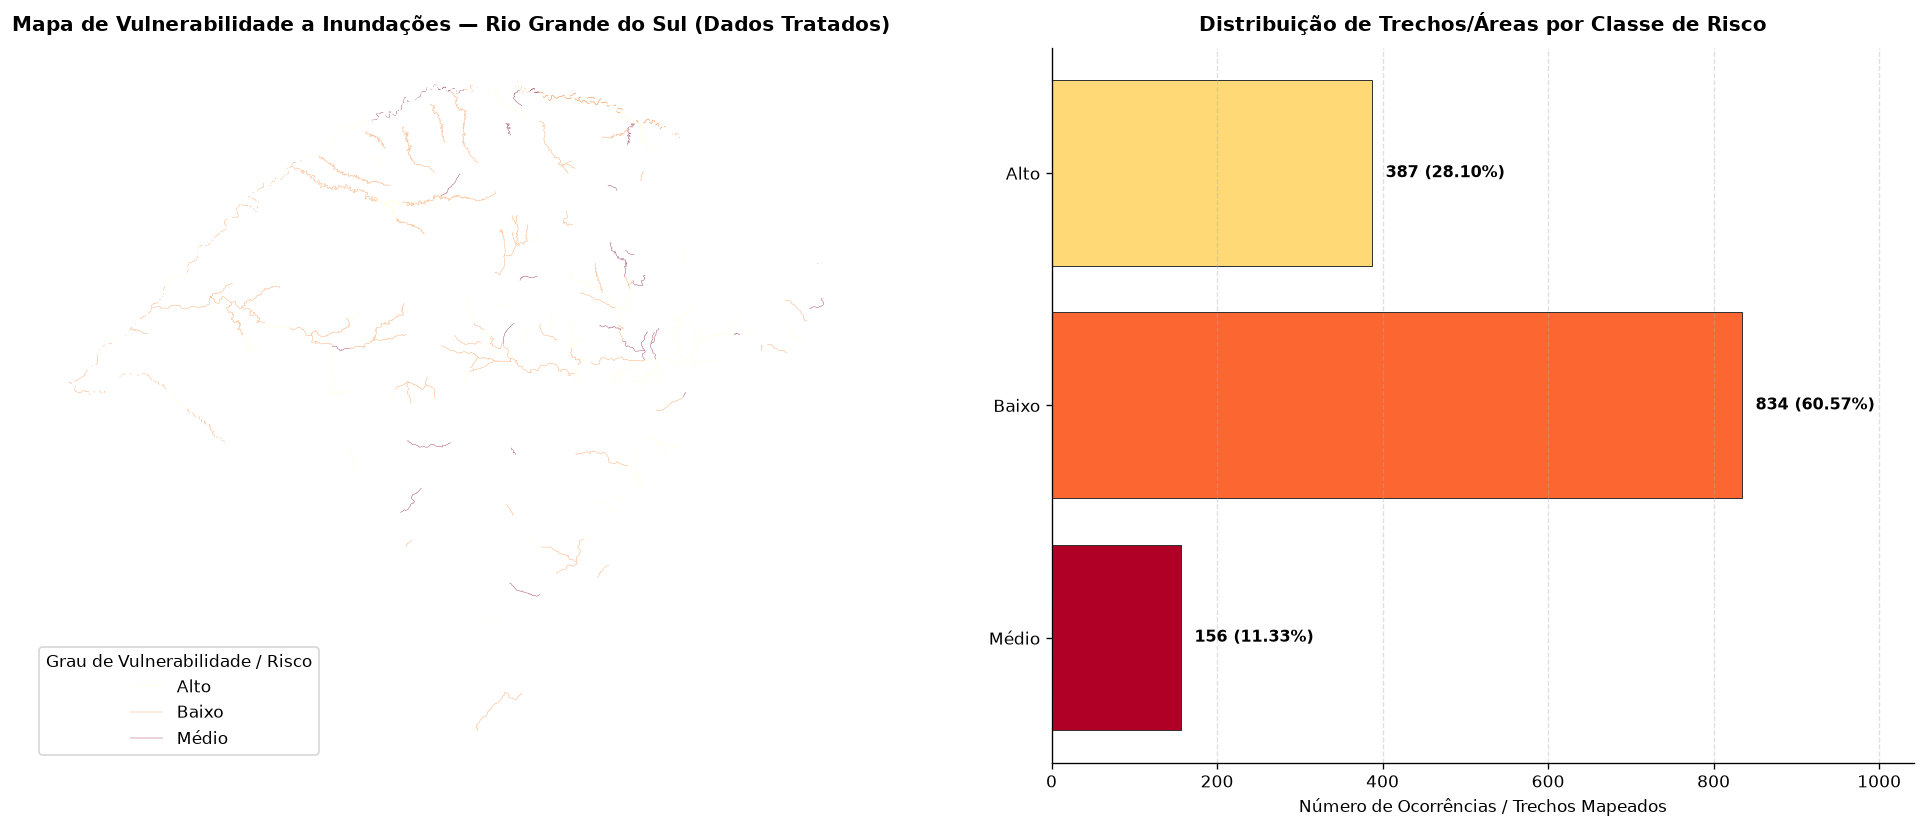

In [7]:
cols_cat = [c for c in gdf_rs.select_dtypes(include=['object', 'string']).columns if c != 'geometry']
col_risco = next((c for c in cols_cat if any(k in c.lower() for k in ['vuln', 'risco', 'classe', 'grau', 'nivel', 'impacto'])), cols_cat[0] if cols_cat else None)
col_mun = next((c for c in cols_cat if any(k in c.lower() for k in ['mun', 'nome', 'nm_'])), None)

print('Coluna de classificação de vulnerabilidade/risco selecionada:', col_risco)
print('Coluna de município identificada:', col_mun)

if col_risco:
    # Ordenação semântica das classes de risco/vulnerabilidade quando aplicável
    ordem_semantica = ['Muito Baixa', 'Baixa', 'Média', 'Alta', 'Muito Alta', 'Não informado']
    categorias_presentes = [c for c in ordem_semantica if c in gdf_rs[col_risco].unique()]
    outras_cats = [c for c in gdf_rs[col_risco].unique() if c not in categorias_presentes]
    ordem_final = categorias_presentes + sorted(outras_cats)

    fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.25, 1]})

    # Painel 1: Mapa Temático de Vulnerabilidade/Risco no RS
    gdf_rs.plot(
        column=col_risco,
        categorical=True,
        categories=ordem_final,
        legend=True,
        cmap='YlOrRd',
        edgecolor='#222222',
        linewidth=0.2,
        legend_kwds={'title': 'Grau de Vulnerabilidade / Risco', 'loc': 'lower left', 'frameon': True},
        ax=axes[0]
    )
    axes[0].set_title('Mapa de Vulnerabilidade a Inundações — Rio Grande do Sul (Dados Tratados)', fontsize=12, fontweight='bold', pad=10)
    axes[0].set_axis_off()

    # Painel 2: Distribuição Absoluta e Percentual por Classe
    contagem = gdf_rs[col_risco].value_counts().reindex(ordem_final).dropna()
    pcts = (contagem / contagem.sum() * 100).round(2)
    cores = plt.cm.YlOrRd(np.linspace(0.25, 0.9, len(contagem)))

    barras = axes[1].barh(contagem.index, contagem.values, color=cores, edgecolor='#333333', linewidth=0.6)
    axes[1].invert_yaxis()
    axes[1].set_title('Distribuição de Trechos/Áreas por Classe de Risco', fontsize=12, fontweight='bold', pad=10)
    axes[1].set_xlabel('Número de Ocorrências / Trechos Mapeados')
    axes[1].grid(axis='x', linestyle='--', alpha=0.4)
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['right'].set_visible(False)

    max_val = contagem.max() if len(contagem) > 0 else 1
    axes[1].set_xlim(0, max_val * 1.25)
    for barra, pct in zip(barras, pcts):
        largura = barra.get_width()
        axes[1].annotate(
            f'{int(largura)} ({pct:.2f}%)',
            (largura + max_val * 0.02, barra.get_y() + barra.get_height() / 2),
            va='center', fontsize=9.5, fontweight='bold'
        )

    plt.tight_layout()
    plt.show()

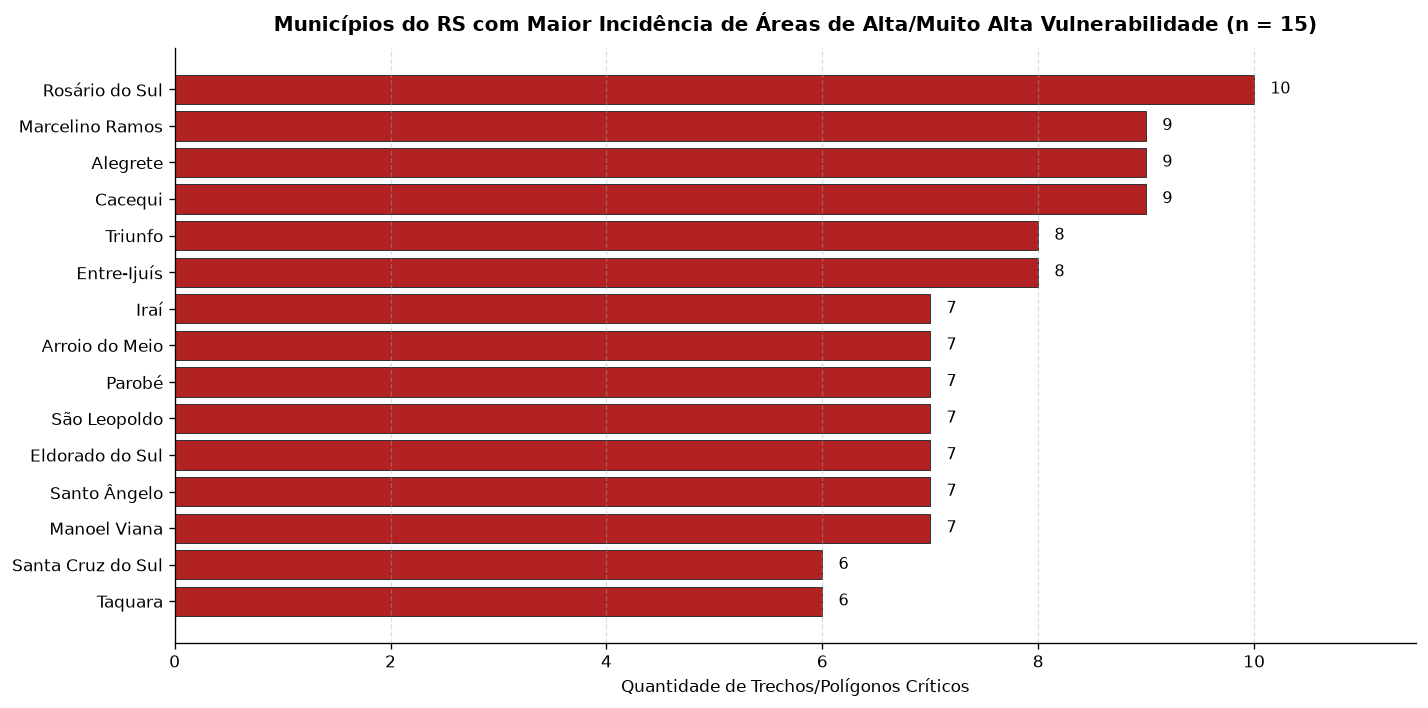

In [11]:
# Top 15 Municípios do RS com maior concentração de áreas de Alta / Muito Alta vulnerabilidade
if col_mun and col_risco:
    classes_criticas = [c for c in gdf_rs[col_risco].unique() if any(k in str(c).lower() for k in ['alta', 'alto', 'crit', 'sever'])]
    base_ranking = gdf_rs[gdf_rs[col_risco].isin(classes_criticas)] if classes_criticas else gdf_rs
    titulo_ranking = titulo_ranking = 'Municípios do RS com Maior Incidência de Áreas de Alta/Muito Alta Vulnerabilidade (n = 15)' if classes_criticas else 'Municípios do RS com Maior Número de Registros Mapeados (n = 15)'

    top_mun = base_ranking[col_mun].value_counts().head(15)
    if len(top_mun) > 0:
        fig, ax = plt.subplots(figsize=(12, 6))
        barras = ax.barh(top_mun.index, top_mun.values, color='#b22222', edgecolor='#333333', linewidth=0.6)
        ax.invert_yaxis()
        ax.set_title(titulo_ranking, fontsize=12, fontweight='bold', pad=10)
        ax.set_xlabel('Quantidade de Trechos/Polígonos Críticos')
        ax.grid(axis='x', linestyle='--', alpha=0.4)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.set_xlim(0, top_mun.max() * 1.15)
        for b in barras:
            w = b.get_width()
            ax.annotate(f'{int(w)}', (w + top_mun.max() * 0.015, b.get_y() + b.get_height() / 2), va='center', fontsize=9.5)
        plt.tight_layout()
        plt.show()

,count,mean,std,min,50%,max
PK,1377.0000,4846.7030,147.7021,4597.0000,4848.0000,5090.0000
GEOCODIGO,1377.0000,4311936.1206,6894.5949,4300034.0000,4312179.0000,4323754.0000
geocodig_1,1377.0000,4311936.1206,6894.5949,4300034.0000,4312179.0000,4323754.0000
total_pop_,1377.0000,31987.9092,91079.1886,0.0000,10032.0000,1360590.0000
total_home,1377.0000,15724.5592,44099.6163,776.0000,4960.0000,654022.0000
total_mulh,1377.0000,16689.9572,50283.7010,690.0000,4918.0000,755917.0000
total_pop1,1377.0000,28169.9775,93800.1777,212.0000,5881.0000,1409939.0000
total_po_1,1377.0000,4244.5389,3763.1725,0.0000,3085.0000,33572.0000
total_po_2,1377.0000,32414.5163,94370.3455,1487.0000,9895.0000,1409939.0000


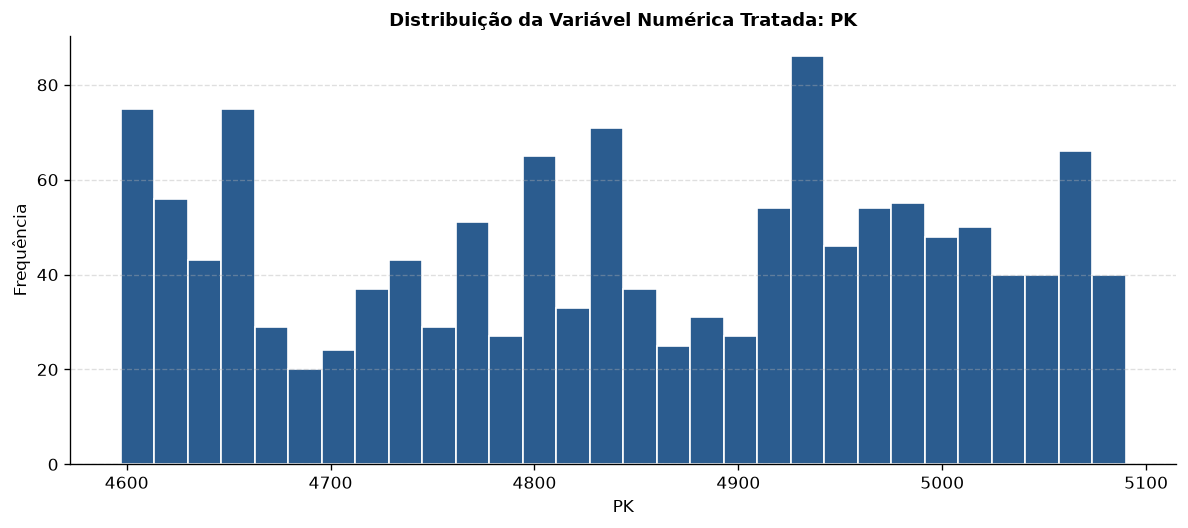

In [9]:
# Análise de variáveis numéricas tratadas (extensão, área ou indicadores hidrográficos)
cols_num_validas = [c for c in gdf_rs.select_dtypes(include=[np.number]).columns if not c.endswith('_flag_nulo') and 'cd_' not in c.lower() and 'id' not in c.lower()]
if cols_num_validas:
    display(gdf_rs[cols_num_validas].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])
    col_num_principal = cols_num_validas[0]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.hist(gdf_rs[col_num_principal], bins=30, color='#2b5c8f', edgecolor='white')
    ax.set_title(f'Distribuição da Variável Numérica Tratada: {col_num_principal}', fontsize=11, fontweight='bold')
    ax.set_xlabel(col_num_principal)
    ax.set_ylabel('Frequência')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

## 8. Exportação da Base Higienizada

In [10]:
gdf_rs.to_file(CAMINHO_SAIDA_GEOJSON, driver='GeoJSON')
print(f'Base geoespacial tratada exportada com sucesso: {CAMINHO_SAIDA_GEOJSON} ({len(gdf_rs)} registros)')

Base geoespacial tratada exportada com sucesso: /home/jo-o-antonio/Downloads/projeto_cpa/rs_vulnerabilidade_inundacoes_tratado.geojson (1377 registros)
